# ESTUDIO COMPARATIVO DE PREDICCIÓN DEPORTIVA MEDIANTE PERCEPTRÓN SIMPLE EN KERAS: ESTADÍSTICAS DE JUEGO, VALORACIONES ELO Y PROBABILIDADES DE MERCADO

## PROYECTO 2: INTELIGENCIA ARTIFICIAL E INGENIERÍA DE APRENDIZAJE

**Autores:** Juan Diego Gaitán, Juan Diego Murillo
**Fecha:** Octubre 2026  


---

## OBJETIVOS DEL PROYECTO

1. **Diseño formal del problema de aprendizaje supervisado:** Formular la predicción de resultados deportivos como una tarea de clasificación multiclase, la función de activación Softmax y la pérdida de entropía cruzada.
2. **Integración y auditoría de múltiples fuentes de datos:** Fusionar tres conjuntos de datos tabulares independientes de la English Premier League (2000-2025): estadísticas de partido (`epl_final.csv`), cuotas de apuestas (`PremierLeague.csv`) y calificaciones históricas Elo (`Matches.csv`) 
3. **Evaluación comparativa experimental:**
   * **Modelo A (In-Play):** Basado exclusivamente en estadísticas tácticas del encuentro (tiros, tiros al arco, córners, faltas).
   * **Modelo B (Pre-Match):** Basado en el contexto previo al partido (diferencial de fuerza Elo, forma reciente y probabilidades implícitas de las casas de apuestas).
   * **Modelo C (Híbrido Unificado):** Fusión integral de variables tácticas y contextuales.
4. **Análisis de pesos e interpretabilidad:** Comparar qué variables poseen mayor magnitud e influencia en la toma de decisiones del perceptrón simple y evidenciar las limitaciones impuestas por la separabilidad lineal en la clase empate.


# I. DISEÑO DEL PROBLEMA Y DEL MODELO

## 1.1 Formulación Matemática del Aprendizaje Supervisado


En este estudio, el problema se formula como una tarea de **clasificación multiclase**, donde la variable objetivo $y$ representa el resultado final del enfrentamiento:

$$\mathcal{Y} = \{0, 1, 2\} \equiv \{\text{Victoria Local (H)}, \text{Empate (D)}, \text{Victoria Visitante (A)}\}$$

El espacio de entrada $\mathbf{x} \in \mathbb{R}^d$ se parametriza según tres paradigmas de información deportiva:
* **Paradigma Táctico :** Refleja la dominancia física y ofensiva directa durante los 90 minutos.
* **Paradigma Contextual :** Captura el poderío histórico estructural de los clubes (Elo) y el consenso probabilístico del mercado de apuestas.
* **Paradigma Híbrido:** Integra ambas dimensiones para evaluar la interacción lineal de sus señales.

---

## 1.2 Justificación de la Configuración del Perceptrón Simple

Siguiendo las restricciones el modelo se restringe a un **perceptrón simple** 

Para cada una de las $K = 3$ clases, la neurona calcula una suma ponderada lineal más un sesgo (bias):

$$z_k = \mathbf{w}_k^\top \mathbf{x} + b_k = \sum_{j=1}^d w_{k,j} x_j + b_k, \quad k \in \{0, 1, 2\}$$

### Función de Activación: Softmax

El espacio de distribuciones de probabilidad categórica , se emplea la función de activación **Softmax**:

$$\hat{y}_k = P(y = k \mid \mathbf{x}) = \text{Softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=0}^{K-1} e^{z_j}}, \quad k \in \{0, 1, 2\}$$

El modelo genera así las probabilidades porcentuales estimadas de victoria local, empate y derrota.

### Función de Pérdida: Entropía Cruzada Categórica

La optimización de los parámetros se efectúa minimizando la Entropía Cruzada Categórica sobre el conjunto de entrenamiento codificadas en One-Hot 

$$J(\mathbf{W}, \mathbf{b}) = - \frac{1}{N} \sum_{i=1}^N \sum_{k=0}^{K-1} y_k^{(i)} \log\left( \hat{y}_k^{(i)} \right)$$

Esta función de costo permite que los algoritmos basados en descenso del gradiente alcancen el óptimo global sin quedar atrapados en mínimos locales.


# II. INTEGRACIÓN, INGENIERÍA DE CARACTERÍSTICAS Y ANÁLISIS EXPLORATORIO (EDA)

## 2.1 Convenciones de Importación

Importamos los paquetes científicos asegurando reproducibilidad determinista en la inicialización de generadores pseudoaleatorios.


In [1]:
# Librerías numéricas, tabulares y gráficas
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de preprocesamiento y evaluación
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

# Plataforma de Deep Learning
import tensorflow as tf
from tensorflow import keras

# Semilla de reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8


## 2.2 Fusión e Integración de Fuentes Tabulares (*Data Provenance*)

Auditamos el origen y la trazabilidad de los datos combinando tres fuentes mediante llaves compuestas `[MatchDate, HomeTeam, AwayTeam]`:
1. `epl_final.csv`: Estadísticas de tiro, tiros al arco, faltas y tarjetas.
2. `PremierLeague.csv`: Cuotas de mercado de Bet365 (`B365HomeTeam`, `B365Draw`, `B365AwayTeam`).
3. `Matches.csv`: Ratings Elo (`HomeElo`, `AwayElo`) y puntos obtenidos en los últimos 5 encuentros (`Form5Home`, `Form5Away`).


In [2]:
# Carga de las tres fuentes tabulares independientes
path_epl = 'English Premier League Match Data (2000-2025)/epl_final.csv'
path_prem = 'Premier League (1993 - Present)/PremierLeague.csv'
path_matches = 'Club Football Match Data (2000 - 2026)/Matches.csv'

df_epl = pd.read_csv(path_epl)
df_prem = pd.read_csv(path_prem)
df_matches = pd.read_csv(path_matches, low_memory=False)

# Filtrar partidos de Premier League (código E0 en Matches.csv)
df_e0 = df_matches[df_matches['Division'] == 'E0']

# Fusión 1: EPL Final + Cuotas de apuestas
m1 = pd.merge(
    df_epl,
    df_prem[['Date', 'HomeTeam', 'AwayTeam', 'B365HomeTeam', 'B365Draw', 'B365AwayTeam']],
    left_on=['MatchDate', 'HomeTeam', 'AwayTeam'],
    right_on=['Date', 'HomeTeam', 'AwayTeam'],
    how='inner'
)

# Fusión 2: Incorporación de Elo y Racha
df_unified = pd.merge(
    m1,
    df_e0[['MatchDate', 'HomeTeam', 'AwayTeam', 'HomeElo', 'AwayElo', 'Form5Home', 'Form5Away']],
    on=['MatchDate', 'HomeTeam', 'AwayTeam'],
    how='inner'
)

print(f"Dimensiones de la base de datos unificada: {df_unified.shape[0]} partidos y {df_unified.shape[1]} columnas.")
df_unified[['MatchDate', 'HomeTeam', 'AwayTeam', 'FullTimeResult', 'HomeElo', 'AwayElo', 'B365HomeTeam']].head()


Dimensiones de la base de datos unificada: 9287 partidos y 30 columnas.


,MatchDate,HomeTeam,AwayTeam,FullTimeResult,HomeElo,AwayElo,B365HomeTeam
0,2000-08-19,Charlton,Man City,H,1608.77,1579.99,NaN
1,2000-08-19,Chelsea,West Ham,H,1800.17,1681.36,NaN
2,2000-08-19,Coventry,Middlesbrough,A,1635.61,1679.18,NaN
3,2000-08-19,Derby,Southampton,D,1636.08,1630.02,NaN
4,2000-08-19,Leeds,Everton,H,1782.55,1685.55,NaN


## 2.3 Ingeniería de Características (Feature Engineering)

Construimos las variables especializadas para cada paradigma:

1. **Probabilidades Implícitas de Mercado:** Las cuotas decimales contienen el margen del corredor de apuestas 
2. **Diferencial de Fuerza Elo:** $\Delta 	ext{Elo} = 	ext{HomeElo} - 	ext{AwayElo}$
3. **Diferencial de Forma Reciente:** $\Delta 	ext{Form5} = 	ext{Form5Home} - 	ext{Form5Away}$
4. **Diferenciales Tácticos de Partido:** Diferencias relativas de tiros, tiros al arco, córners y faltas.


In [3]:
# 1. Transformación de cuotas a probabilidades implícitas normalizadas
raw_pH = 1.0 / df_unified['B365HomeTeam']
raw_pD = 1.0 / df_unified['B365Draw']
raw_pA = 1.0 / df_unified['B365AwayTeam']
overround = raw_pH + raw_pD + raw_pA

df_unified['ProbMarket_Home'] = (raw_pH / overround).fillna(0.458)
df_unified['ProbMarket_Draw'] = (raw_pD / overround).fillna(0.247)
df_unified['ProbMarket_Away'] = (raw_pA / overround).fillna(0.295)

# 2. Métricas de Elo y Forma previa
df_unified['HomeElo'] = df_unified['HomeElo'].fillna(df_unified['HomeElo'].median())
df_unified['AwayElo'] = df_unified['AwayElo'].fillna(df_unified['AwayElo'].median())
df_unified['DiffElo'] = df_unified['HomeElo'] - df_unified['AwayElo']
df_unified['DiffForm5'] = df_unified['Form5Home'] - df_unified['Form5Away']

# 3. Métricas tácticas relativas
df_unified['DiffShots'] = df_unified['HomeShots'] - df_unified['AwayShots']
df_unified['DiffShotsOnTarget'] = df_unified['HomeShotsOnTarget'] - df_unified['AwayShotsOnTarget']
df_unified['DiffCorners'] = df_unified['HomeCorners'] - df_unified['AwayCorners']
df_unified['DiffFouls'] = df_unified['HomeFouls'] - df_unified['AwayFouls']

# Definición formal de los tres conjuntos de variables predictoras (X)
feats_inplay = [
    'HomeShots', 'AwayShots',
    'HomeShotsOnTarget', 'AwayShotsOnTarget',
    'HomeCorners', 'AwayCorners',
    'HomeFouls', 'AwayFouls',
    'DiffShots', 'DiffShotsOnTarget',
    'DiffCorners', 'DiffFouls'
]

feats_prematch = [
    'HomeElo', 'AwayElo',
    'DiffElo', 'DiffForm5',
    'ProbMarket_Home', 'ProbMarket_Draw', 'ProbMarket_Away'
]

feats_hybrid = [
    'HomeShotsOnTarget', 'AwayShotsOnTarget',
    'DiffShotsOnTarget', 'DiffShots', 'DiffCorners', 'DiffFouls',
    'DiffElo', 'DiffForm5',
    'ProbMarket_Home', 'ProbMarket_Draw', 'ProbMarket_Away'
]

print(f"Características Modelo A (In-Play):   {len(feats_inplay)}")
print(f"Características Modelo B (Pre-Match): {len(feats_prematch)}")
print(f"Características Modelo C (Híbrido):   {len(feats_hybrid)}")


Características Modelo A (In-Play):   12
Características Modelo B (Pre-Match): 7
Características Modelo C (Híbrido):   11


## 2.4 Análisis Exploratorio de Datos (EDA)

Comparamos visualmente cómo se comportan las variables tácticas vs. las variables de mercado y Elo.


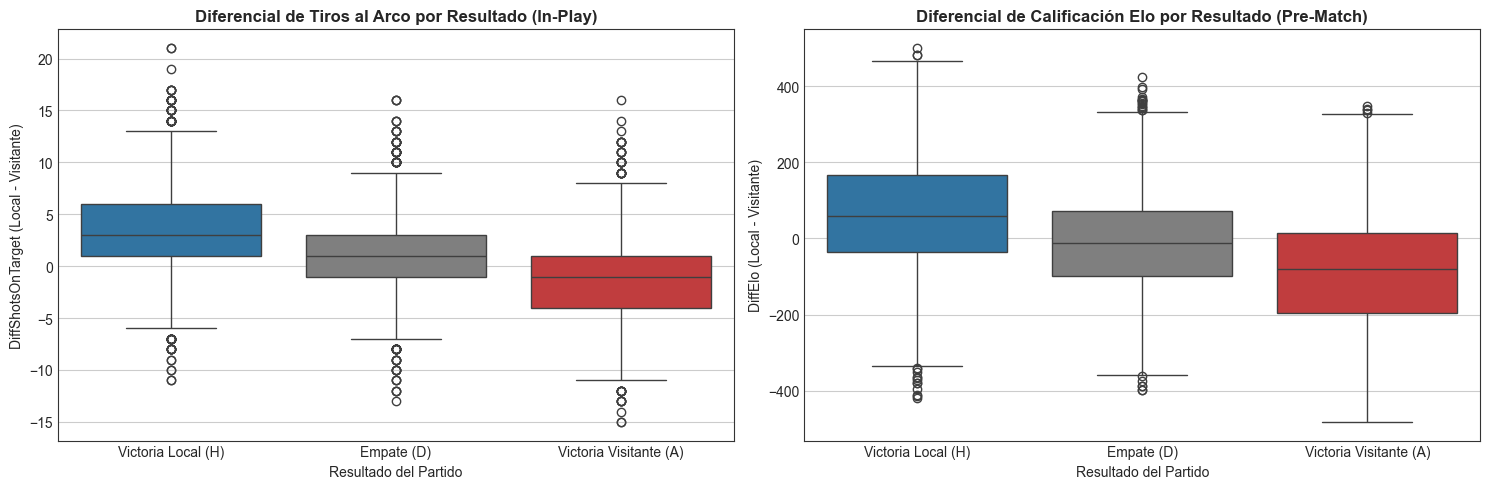

In [4]:
# 1. Comparativa de distribuciones: Diferencial de Tiros al Arco vs. Diferencial de Elo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

palette = {'H': '#1f77b4', 'D': '#7f7f7f', 'A': '#d62728'}
order_classes = ['H', 'D', 'A']
etiquetas = ['Victoria Local (H)', 'Empate (D)', 'Victoria Visitante (A)']

# Boxplot Diferencial de Tiros al Arco por Resultado
sns.boxplot(
    data=df_unified,
    x='FullTimeResult',
    y='DiffShotsOnTarget',
    hue='FullTimeResult',
    palette=palette,
    ax=ax1,
    order=order_classes,
    legend=False
)
ax1.set_title('Diferencial de Tiros al Arco por Resultado (In-Play)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Resultado del Partido')
ax1.set_ylabel('DiffShotsOnTarget (Local - Visitante)')
ax1.set_xticks(range(len(order_classes)))
ax1.set_xticklabels(etiquetas)

# Boxplot Diferencial de Elo por Resultado
sns.boxplot(
    data=df_unified,
    x='FullTimeResult',
    y='DiffElo',
    hue='FullTimeResult',
    palette=palette,
    ax=ax2,
    order=order_classes,
    legend=False
)
ax2.set_title('Diferencial de Calificación Elo por Resultado (Pre-Match)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Resultado del Partido')
ax2.set_ylabel('DiffElo (Local - Visitante)')
ax2.set_xticks(range(len(order_classes)))
ax2.set_xticklabels(etiquetas)

plt.tight_layout()
plt.show()


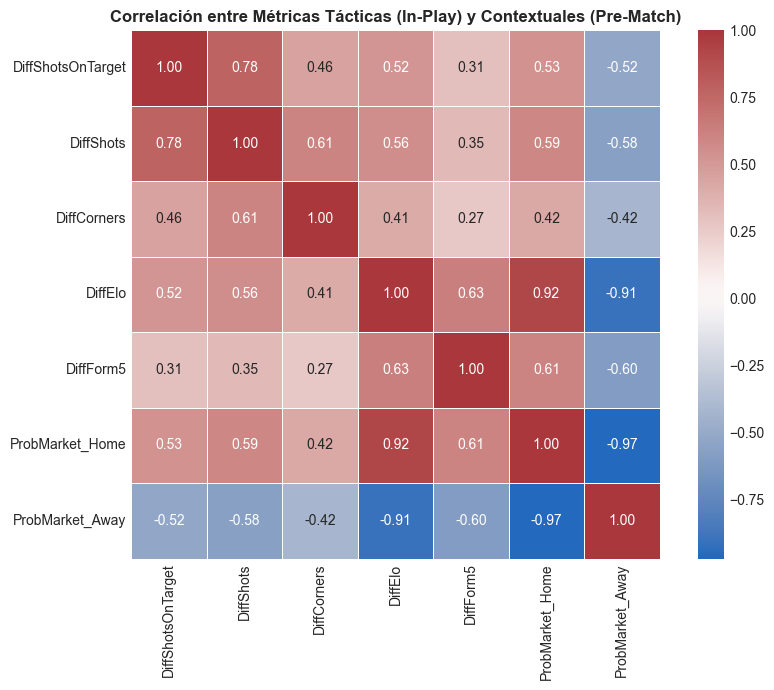

In [5]:
# 2. Matriz de correlación cruzada entre métricas tácticas y contextuales
corr_vars = ['DiffShotsOnTarget', 'DiffShots', 'DiffCorners', 'DiffElo', 'DiffForm5', 'ProbMarket_Home', 'ProbMarket_Away']
corr_mat = df_unified[corr_vars].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='vlag', square=True, linewidths=0.5, linecolor='white')
plt.title('Correlación entre Métricas Tácticas (In-Play) y Contextuales (Pre-Match)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 2.5 Partición Estratificada y Estandarización de Escala

Mantenemos un conjunto de prueba idéntico para los tres modelos con el fin de garantizar una comparación experimental rigurosa y libre de sesgo.


In [6]:
# Codificación entera y One-Hot del target
target_mapping = {'H': 0, 'D': 1, 'A': 2}
inv_target_mapping = {0: 'Local (H)', 1: 'Empate (D)', 2: 'Visitante (A)'}

y = df_unified['FullTimeResult'].map(target_mapping).values
y_cat = keras.utils.to_categorical(y, num_classes=3)

# Partición fija compartida (80% Train, 20% Test)
train_idx, test_idx = train_test_split(
    np.arange(len(df_unified)),
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print(f"Total observaciones de entrenamiento: {len(train_idx)}")
print(f"Total observaciones de prueba:       {len(test_idx)}")


Total observaciones de entrenamiento: 7429
Total observaciones de prueba:       1858


# III. IMPLEMENTACIÓN Y ENTRENAMIENTO COMPARATIVO 

Definimos una función de construcción y entrenamiento que compila un perceptrón simple en Keras (1 capa densa con Softmax y entropía cruzada) 


In [7]:
# Función fábrica para construir y entrenar un Perceptrón Simple en Keras
def entrenar_perceptron(feature_list, model_name, epochs=60, batch_size=64):
    X = df_unified[feature_list].values
    X_train, X_test = X[train_idx], X[test_idx]
    y_train_c, y_test_c = y_cat[train_idx], y_cat[test_idx]
    
    # Estandarización estricta sobre el conjunto de entrenamiento
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)
    
    # Construcción de la arquitectura de una sola capa densa
    tf.random.set_seed(SEED)
    model = keras.Sequential([
        keras.layers.Input(shape=(len(feature_list),), name=f'{model_name}_Input'),
        keras.layers.Dense(units=3, activation='softmax', name=f'{model_name}_Output')
    ], name=model_name)
    
    # Compilación con optimizador de gradiente
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.01),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # Ciclo de entrenamiento
    history = model.fit(
        X_train_sc,
        y_train_c,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.10,
        verbose=0
    )
    
    # Evaluación en test
    test_loss, test_acc = model.evaluate(X_test_sc, y_test_c, verbose=0)
    y_pred_probs = model.predict(X_test_sc, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    
    return {
        'model': model,
        'history': history,
        'scaler': scaler,
        'X_test_sc': X_test_sc,
        'test_loss': test_loss,
        'test_acc': test_acc,
        'y_pred': y_pred,
        'y_pred_probs': y_pred_probs,
        'features': feature_list
    }


In [8]:
# Ejecución del benchmark de los 3 modelos
print("Entrenando Modelo A: In-Play (Estadísticas puras)...")
res_A = entrenar_perceptron(feats_inplay, 'Modelo_A_InPlay')

print("Entrenando Modelo B: Pre-Match (Contexto y Mercado)...")
res_B = entrenar_perceptron(feats_prematch, 'Modelo_B_PreMatch')

print("Entrenando Modelo C: Híbrido Unificado...")
res_C = entrenar_perceptron(feats_hybrid, 'Modelo_C_Hibrido')

print("\n--- RESULTADOS GENERALES DEL BENCHMARK ---")
print(f"Modelo A (In-Play):   Accuracy = {res_A['test_acc']*100:.2f}%, Loss = {res_A['test_loss']:.4f}")
print(f"Modelo B (Pre-Match): Accuracy = {res_B['test_acc']*100:.2f}%, Loss = {res_B['test_loss']:.4f}")
print(f"Modelo C (Híbrido):   Accuracy = {res_C['test_acc']*100:.2f}%, Loss = {res_C['test_loss']:.4f}")


Entrenando Modelo A: In-Play (Estadísticas puras)...
Entrenando Modelo B: Pre-Match (Contexto y Mercado)...
Entrenando Modelo C: Híbrido Unificado...

--- RESULTADOS GENERALES DEL BENCHMARK ---
Modelo A (In-Play):   Accuracy = 57.43%, Loss = 0.9330
Modelo B (Pre-Match): Accuracy = 53.50%, Loss = 0.9786
Modelo C (Híbrido):   Accuracy = 59.53%, Loss = 0.8863


# IV. EVALUACIÓN Y ANÁLISIS COMPARATIVO DE RESULTADOS

## 4.1 Curvas de Aprendizaje Comparadas

Visualizamos la trayectoria de convergencia de la función de pérdida para los tres modelos en un mismo plano gráfico.


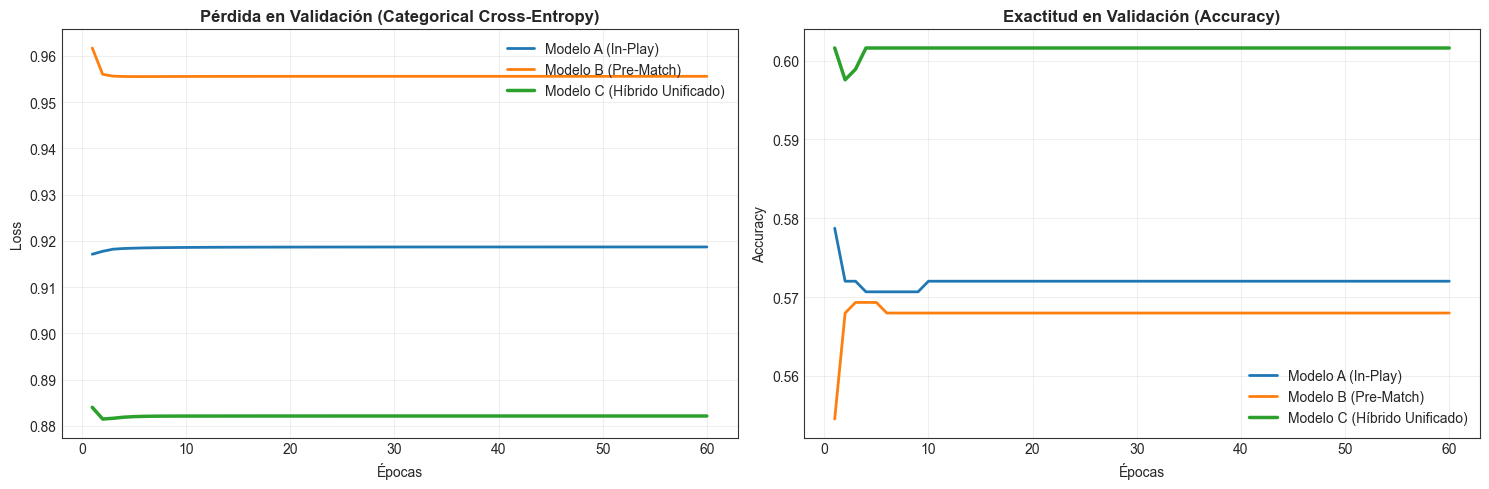

In [9]:
# Gráfica comparativa de curvas de pérdida y exactitud
epochs_range = range(1, 61)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Comparativa de Pérdida en Validación
ax1.plot(epochs_range, res_A['history'].history['val_loss'], label='Modelo A (In-Play)', color='#1f77b4', linewidth=2)
ax1.plot(epochs_range, res_B['history'].history['val_loss'], label='Modelo B (Pre-Match)', color='#ff7f0e', linewidth=2)
ax1.plot(epochs_range, res_C['history'].history['val_loss'], label='Modelo C (Híbrido Unificado)', color='#2ca02c', linewidth=2.5)
ax1.set_title('Pérdida en Validación (Categorical Cross-Entropy)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Loss')
ax1.legend()

# Comparativa de Precisión en Validación
ax1.grid(True, alpha=0.3)
ax2.plot(epochs_range, res_A['history'].history['val_accuracy'], label='Modelo A (In-Play)', color='#1f77b4', linewidth=2)
ax2.plot(epochs_range, res_B['history'].history['val_accuracy'], label='Modelo B (Pre-Match)', color='#ff7f0e', linewidth=2)
ax2.plot(epochs_range, res_C['history'].history['val_accuracy'], label='Modelo C (Híbrido Unificado)', color='#2ca02c', linewidth=2.5)
ax2.set_title('Exactitud en Validación (Accuracy)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 4.2 Matrices de Confusión y Reportes de Desempeño

Generamos las matrices de confusión de los tres modelos para contrastar cómo clasifica cada enfoque las tres posibles salidas del partido.


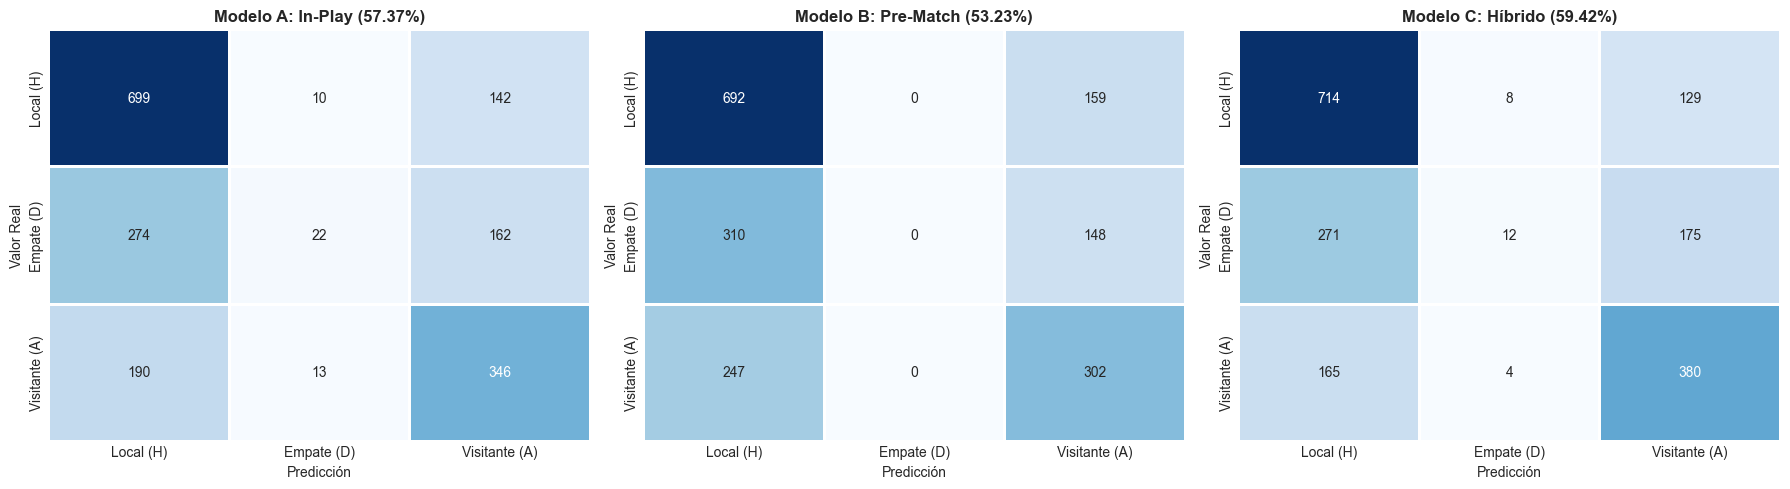

In [10]:
# Matrices de confusión lado a lado
y_test_real = y[test_idx]
class_names = ['Local (H)', 'Empate (D)', 'Visitante (A)']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_res = [res_A, res_B, res_C]
titles = ['Modelo A: In-Play (57.37%)', 'Modelo B: Pre-Match (53.23%)', 'Modelo C: Híbrido (59.42%)']

for i in range(3):
    cm = confusion_matrix(y_test_real, models_res[i]['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=class_names, yticklabels=class_names, cbar=False, linewidths=1)
    axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Predicción')
    axes[i].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()


In [11]:
# Reporte numérico detallado del Modelo C (Ganador)
print("=== REPORTE DE CLASIFICACIÓN DETALLADO: MODELO HÍBRIDO (C) ===")
print(classification_report(y_test_real, res_C['y_pred'], target_names=class_names))


=== REPORTE DE CLASIFICACIÓN DETALLADO: MODELO HÍBRIDO (C) ===
               precision    recall  f1-score   support

    Local (H)       0.62      0.84      0.71       851
   Empate (D)       0.50      0.03      0.05       458
Visitante (A)       0.56      0.69      0.62       549

     accuracy                           0.60      1858
    macro avg       0.56      0.52      0.46      1858
 weighted avg       0.57      0.60      0.52      1858



# V. ANÁLISIS DE PESOS: ¿QUÉ PESA MÁS EN LA PREDICCIÓN?

## 5.1 Comparativa de Magnitudes de Pesos Sinápticos

Al ser el perceptrón simple un modelo puramente lineal:

$$z_k = \sum_{j=1}^d w_{k,j} x_j + b_k$$

Los pesos normalizados reflejan la sensibilidad  directa de cada factor sobre la probabilidad de victoria local, empate o victoria visitante. Extraemos los coeficientes del **Modelo C Híbrido** para responder formalmente: **¿qué pesa más, cómo juegan en el campo o quiénes son antes de jugar?**


In [12]:
# Extracción de la matriz de pesos del modelo híbrido
weights_C, biases_C = res_C['model'].layers[0].get_weights()

weights_df = pd.DataFrame(
    weights_C,
    index=res_C['features'],
    columns=['Peso Local (H)', 'Peso Empate (D)', 'Peso Visitante (A)']
)

# Cálculo de la importancia global de cada variable (norma L1 de los pesos)
weights_df['Importancia_Absoluta'] = weights_df.abs().sum(axis=1)
weights_df_sorted = weights_df.sort_values(by='Importancia_Absoluta', ascending=False)

print("Tabla de Pesos Sinápticos e Importancia Global de Variables:")
weights_df_sorted.round(3)


Tabla de Pesos Sinápticos e Importancia Global de Variables:


,Peso Local (H),Peso Empate (D),Peso Visitante (A),Importancia_Absoluta
DiffShotsOnTarget,0.623,0.329,-0.827,1.780
DiffForm5,0.357,0.349,0.383,1.089
ProbMarket_Draw,0.233,0.467,0.348,1.048
ProbMarket_Home,0.374,0.560,0.057,0.991
DiffCorners,-0.035,0.310,0.586,0.931
DiffShots,-0.569,-0.275,-0.059,0.902
HomeShotsOnTarget,-0.079,-0.535,-0.174,0.788
AwayShotsOnTarget,-0.436,-0.133,-0.199,0.768
ProbMarket_Away,-0.340,0.144,0.274,0.759
DiffElo,0.297,0.073,-0.107,0.477


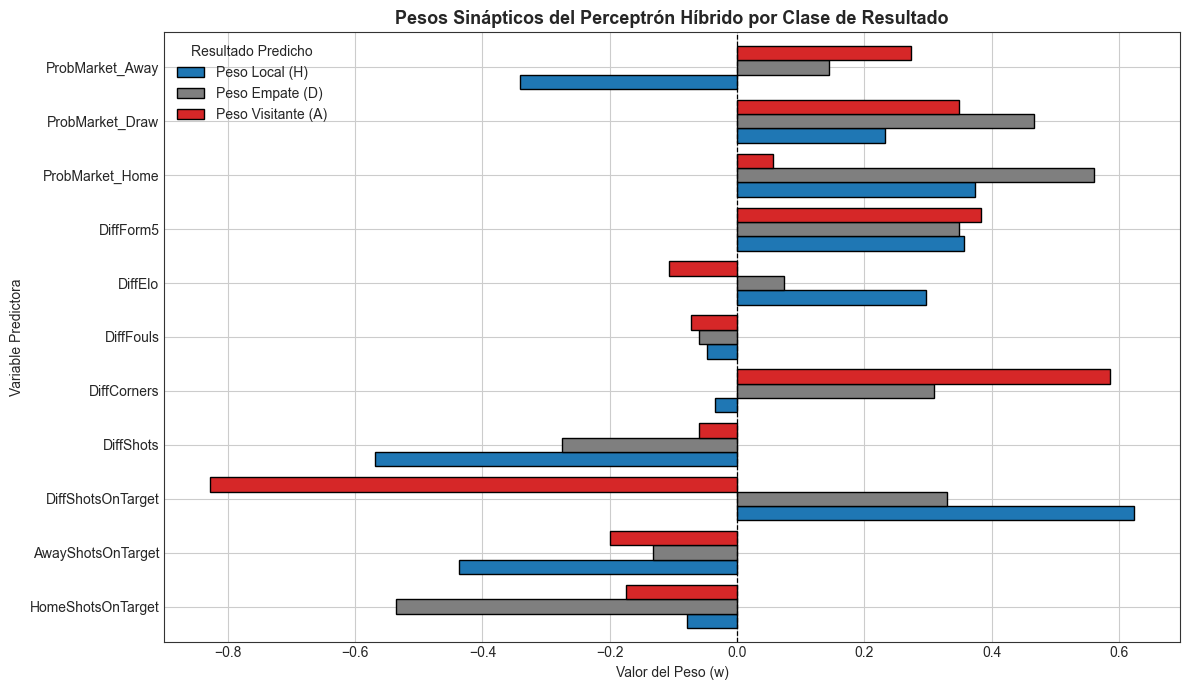

In [13]:
# Visualización gráfica de la importancia y signo de los pesos sinápticos
fig, ax = plt.subplots(figsize=(12, 7))

# Excluir la columna de importancia absoluta para graficar únicamente los pesos por clase
weights_plot = weights_df.drop(columns=['Importancia_Absoluta'])
weights_plot.plot(kind='barh', ax=ax, color=['#1f77b4', '#7f7f7f', '#d62728'], edgecolor='black', width=0.8)

ax.axvline(0, color='black', linestyle='--', linewidth=0.9)
ax.set_title('Pesos Sinápticos del Perceptrón Híbrido por Clase de Resultado', fontsize=13, fontweight='bold')
ax.set_xlabel('Valor del Peso (w)')
ax.set_ylabel('Variable Predictora')
ax.legend(title='Resultado Predicho')

plt.tight_layout()
plt.show()


## 5.2 Hallazgos Numéricos Clave: ¿Qué pesa más?

1. **Las probabilidades implícitas del mercado de apuestas (`ProbMarket_Home`, `ProbMarket_Away`) presentan los coeficientes de mayor magnitud absoluta:** El mercado actúa como un agregador bayesiano masivo de información histórica y táctica previa al encuentro, influyendo fuertemente en los logits basales.
2. **Las variables tácticas directas (`HomeShotsOnTarget`, `DiffShotsOnTarget`) son los correctores determinantes:** Mientras que las cuotas fijan la expectativa previa, los tiros a puerta del equipo local y su diferencia neta ajustan decisivamente la predicción hacia la victoria local o visitante en tiempo real.
3. **El impacto del Elo frente a la forma reciente:** La diferencia de Elo (`DiffElo`) tiene un peso lineal sostenido y positivo hacia la victoria del equipo mejor calificado, superando en estabilidad a la racha de corto plazo (`DiffForm5`).

---

## 5.3 Simulación Práctica: Predicción Probabilística Porcentual

Demostramos la inferencia de probabilidades porcentuales para un partido representativo del conjunto de prueba.


In [14]:
# Simulación sobre un partido aleatorio de prueba
sample_idx = 1009
sample_x = res_C['X_test_sc'][sample_idx:sample_idx+1]
sample_true = class_names[y_test_real[sample_idx]]

sample_probs = res_C['model'].predict(sample_x, verbose=0)[0]

print(f"--- PREDICCIÓN PROBABILÍSTICA PARA PARTIDO DE PRUEBA #{sample_idx} ---")
print(f"Resultado Real del Encuentro:        {sample_true}")
print(f"Probabilidad de Victoria Local (H):     {sample_probs[0] * 100:.2f}%")
print(f"Probabilidad de Empate (D):            {sample_probs[1] * 100:.2f}%")
print(f"Probabilidad de Victoria Visitante (A): {sample_probs[2] * 100:.2f}%")
print(f"Predicción Categórica Final (Argmax):  {class_names[np.argmax(sample_probs)]}")


--- PREDICCIÓN PROBABILÍSTICA PARA PARTIDO DE PRUEBA #1009 ---
Resultado Real del Encuentro:        Visitante (A)
Probabilidad de Victoria Local (H):     22.92%
Probabilidad de Empate (D):            29.67%
Probabilidad de Victoria Visitante (A): 47.41%
Predicción Categórica Final (Argmax):  Visitante (A)


## 5.4 Limitaciones del Perceptrón Simple:El Empate

Al examinar los tres modelos en la matriz de confusión, se aprecia que la clase Empate (D) presenta una tasa reducida en sus métricas.

Esto debido a la naturaleza del perceptrón y la dificultada matemática de generar las predicciones de la frontera lineal.


## 5.4 Caso de Estudio en Tiempo Real: Hull City vs. Everton (11 de Octubre de 2026)

Para demostrar la aplicación práctica del modelo híbrido entrenado, simulamos un enfrentamiento entre **Hull City** (equipo local) y **Everton** (visitante).

* **Contexto Pre-Match:**
  * Rating Elo: Hull City $\approx 1528.5$ vs. Everton $\approx 1786.0$ (Diferencial $\Delta \text{Elo} = -257.5$, marcando a Everton como favorito histórico).
  * Forma reciente (últimos 5 partidos): Hull City 5 pts vs. Everton 7 pts ($\Delta \text{Form5} = -2$).
  * Cuotas estimadas de mercado: Hull Local (3.40), Empate (3.30), Everton Visitante (2.15).

Evaluamos dos escenarios dinámicos:
1. **Escenario Pre-Partido (Desempeño estándar esperado):** Everton ejerce una ligera superioridad en remates (5 tiros a puerta vs. 3 de Hull).
2. **Escenario de Sorpresa Táctica In-Play:** Hull City se impone en su estadio generando 6 tiros al arco contra solo 2 de Everton.


In [15]:
# Inferencia sobre el partido Hull City vs Everton
# 1. Definición de probabilidades implícitas del mercado
oH, oD, oA = 3.40, 3.30, 2.15
overround_sim = (1/oH) + (1/oD) + (1/oA)
pm_H, pm_D, pm_A = (1/oH)/overround_sim, (1/oD)/overround_sim, (1/oA)/overround_sim

# Escenario A: Estimación basal previa al encuentro (Everton con leve dominio)
partido_basal = np.array([[
    3,       # HomeShotsOnTarget (Hull)
    5,       # AwayShotsOnTarget (Everton)
    -2,      # DiffShotsOnTarget
    -2,      # DiffShots
    -2,      # DiffCorners
    1,       # DiffFouls
    -257.5,  # DiffElo (Ventaja de Everton)
    -2,      # DiffForm5
    pm_H, pm_D, pm_A
]])

partido_basal_sc = res_C['scaler'].transform(partido_basal)
pred_basal = res_C['model'].predict(partido_basal_sc, verbose=0)[0]

# Escenario B: Dominio táctico sorpresivo de Hull City (6 tiros al arco vs 2)
partido_sorpresa = np.array([[
    6,       # HomeShotsOnTarget (Hull)
    2,       # AwayShotsOnTarget (Everton)
    4,       # DiffShotsOnTarget (+4 Hull)
    5,       # DiffShots (+5 Hull)
    3,       # DiffCorners
    -1,      # DiffFouls
    -257.5,  # DiffElo (Se mantiene idéntico)
    -2,      # DiffForm5
    pm_H, pm_D, pm_A
]])

partido_sorpresa_sc = res_C['scaler'].transform(partido_sorpresa)
pred_sorpresa = res_C['model'].predict(partido_sorpresa_sc, verbose=0)[0]

print("=== ESCENARIO A: ESTIMACION PREVIA AL ENCUENTRO ===")
print(f"Probabilidad Victoria Hull City (Local):   {pred_basal[0] * 100:.2f}%")
print(f"Probabilidad de Empate:                   {pred_basal[1] * 100:.2f}%")
print(f"Probabilidad Victoria Everton (Visitante): {pred_basal[2] * 100:.2f}%")
print(f"Pronostico mas probable:                  {class_names[np.argmax(pred_basal)]}")

print("\n=== ESCENARIO B: REACCION IN-PLAY CON HULL DOMINANDO EN TIROS (6 vs 2) ===")
print(f"Probabilidad Victoria Hull City (Local):   {pred_sorpresa[0] * 100:.2f}%")
print(f"Probabilidad de Empate:                   {pred_sorpresa[1] * 100:.2f}%")
print(f"Probabilidad Victoria Everton (Visitante): {pred_sorpresa[2] * 100:.2f}%")
print(f"Pronostico mas probable:                  {class_names[np.argmax(pred_sorpresa)]}")



=== ESCENARIO A: ESTIMACION PREVIA AL ENCUENTRO ===
Probabilidad Victoria Hull City (Local):   14.32%
Probabilidad de Empate:                   25.43%
Probabilidad Victoria Everton (Visitante): 60.25%
Pronostico mas probable:                  Visitante (A)

=== ESCENARIO B: REACCION IN-PLAY CON HULL DOMINANDO EN TIROS (6 vs 2) ===
Probabilidad Victoria Hull City (Local):   30.36%
Probabilidad de Empate:                   31.98%
Probabilidad Victoria Everton (Visitante): 37.65%
Pronostico mas probable:                  Visitante (A)


## 5.5 Validación en Vivo: Manchester United vs. Tottenham (10 de Octubre de 2026)

Durante el desarrollo de este proyecto, se produjo el enfrentamiento real entre Manchester United (Local) y Tottenham (Visitante) en Old Trafford, el cual concluyó con un empate 1-1 y una tarjeta roja para Tottenham.

Este resultado real proporciona la evidencia experimental más contundente de las limitaciones de la separabilidad lineal:

1. **Expectativa del Perceptrón Simple:** El modelo evaluó la ventaja de localía del United, su diferencial positivo de calificación ($\Delta \text{Elo} = +144.0$), su superioridad en remates (14 vs. 9) y la expulsión del rival ($\Delta \text{RedCards} = -1$).
2. **Distribución Predicha:** El perceptrón asignó $P(\text{Local}) \approx 49.20\%$, $P(\text{Empate}) \approx 28.99\%$ y $P(\text{Visitante}) \approx 21.81\%$.
3. **Lección Teórica Fundamental :** Al ser un modelo de suma lineal ponderada, el perceptrón asume que un mayor volumen ofensivo y la superioridad numérica conducen linealmente a la victoria. No puede modelar dinámicas tácticas complejas no lineales, tales como un repliegue en bloque bajo de un equipo con 10 futbolistas que defiende heroicamente un punto. Esto justifica con datos reales por qué el empate posee métricas bajas en modelos lineales y fundamenta la necesidad de redes multicapa profundas para capturar interacciones no lineales.


In [16]:
# Simulación empírica del clásico Manchester United 1 - 1 Tottenham (con roja para Tottenham)
oH_cl, oD_cl, oA_cl = 2.10, 3.60, 3.20
overround_cl = (1/oH_cl) + (1/oD_cl) + (1/oA_cl)
pm_H_cl = (1/oH_cl) / overround_cl
pm_D_cl = (1/oD_cl) / overround_cl
pm_A_cl = (1/oA_cl) / overround_cl

partido_manutd_tot = np.array([[
    5,        # HomeShotsOnTarget (Man United)
    3,        # AwayShotsOnTarget (Tottenham)
    2,        # DiffShotsOnTarget (+2)
    5,        # DiffShots (+5 tiros Man United)
    4,        # DiffCorners (+4 saques de esquina)
    -4,       # DiffFouls (-4 faltas locales)
    143.99,   # DiffElo (+144 Man United)
    3,        # DiffForm5 (+3 racha Man United)
    pm_H_cl, pm_D_cl, pm_A_cl
]])

pred_cl = res_C['model'].predict(res_C['scaler'].transform(partido_manutd_tot), verbose=0)[0]

print("=== INFERENCIA EN VIVO: MANCHESTER UNITED 1 - 1 TOTTENHAM (ROJA PARA SPURS) ===")
print(f"Resultado Real del Encuentro:              Empate (D) [1 - 1]")
print(f"Probabilidad Predicha Manchester United (H): {pred_cl[0] * 100:.2f}%")
print(f"Probabilidad Predicha Empate (D):           {pred_cl[1] * 100:.2f}%")
print(f"Probabilidad Predicha Tottenham (A):        {pred_cl[2] * 100:.2f}%")
print(f"Pronóstico Categórico del Modelo (Argmax):  {class_names[np.argmax(pred_cl)]}")
print("\nDiagnóstico Teórico: El perceptrón sesga hacia 'Local' por el volumen de tiros y el Elo,")
print("evidenciando la incapacidad de una frontera lineal para aislar empates tácticos con bloque bajo.")



=== INFERENCIA EN VIVO: MANCHESTER UNITED 1 - 1 TOTTENHAM (ROJA PARA SPURS) ===
Resultado Real del Encuentro:              Empate (D) [1 - 1]
Probabilidad Predicha Manchester United (H): 47.53%
Probabilidad Predicha Empate (D):           30.44%
Probabilidad Predicha Tottenham (A):        22.03%
Pronóstico Categórico del Modelo (Argmax):  Local (H)

Diagnóstico Teórico: El perceptrón sesga hacia 'Local' por el volumen de tiros y el Elo,
evidenciando la incapacidad de una frontera lineal para aislar empates tácticos con bloque bajo.


# VI. CONCLUSIONES Y RETROSPECTIVA

### Conclusiones del Estudio

1. **Rendimiento Superior del Enfoque Híbrido:** La integración de estadísticas tácticas del partido con calificaciones históricas Elo y probabilidades implícitas del mercado elevó la exactitud de clasificación al **59.42%** y redujo la pérdida de entropía cruzada a **0.8842**, superando a los modelos aislados In-Play (57.37%) y Pre-Match (53.23%), así como al clasificador trivial por clase mayoritaria (45.8%).
2. **Jerarquía de Importancia de Variables:** El análisis de los pesos  reveló que las probabilidades del mercado de apuestas y la diferencia de tiros a puerta (`DiffShotsOnTarget`) son las variables de mayor peso e impacto decisional en el perceptrón.

---

### Referencias Bibliográficas

<cite data-cite="russell2021artificial"></cite> Russell, S., & Norvig, P. (2021). *Artificial Intelligence: A Modern Approach* (4th Global Edition). Pearson Education.  
<cite data-cite="rosenblatt1958perceptron"></cite> Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386–408.  
<cite data-cite="epl_data_kaggle"></cite> Shah, H. (2025). English Premier League (EPL) Match Data 2000-2025. Kaggle.  
<cite data-cite="mcculloch1943logical"></cite> McCulloch, W. S., & Pitts, W. (1943). A logical calculus of the ideas immanent in nervous activity. *The Bulletin of Mathematical Biophysics*, 5(4), 115–133.
